# Infer Linked Ancestry from the Same Forward Sample

Use H1–H12 from chromosome 1 of the founder-and-expansion population.
Give only phased alleles, variant positions, analyzed length and the mutation
rate to inference. Reveal separately recorded point genealogies afterward.
Coalescent simulation below uses the same demographic size schedule,
12 copies, chromosome length, map length and mutation rate.


In [1]:
library(hpgR)
options(repr.plot.width = 10, repr.plot.height = 4.5,
        repr.plot.pointsize = 14, warn = 1)
truth_color <- "#B33B32"
estimate_color <- "#265991"
drawFigure <- function(name, draw, width = 10, height = 4.5) {
    options(repr.plot.width = width, repr.plot.height = height)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width,
            height = height, pointsize = 14, family = "Helvetica",
            useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


In [2]:
observed <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


ancestry_truth <- (function() {
  encoded <- c(
    "H4sIAAAAAAAAA+1dXWwj13U+IoeUqJ/d0UorB0VSEAsjNoKNsdL6ZzeOs7TWP2vXa3iRBnAbOFpKHEnsSiSXpGI3TRACRYC8pCjQ",
    "h/4X2zovQdEiQRDAeUggdP3SB6MG+tAnA5sWCGI7aV3krQXqzuU938yZwyEl7lJcUZoFuN/cO3Pvmcv55p6P554ZvTpJRGlyMmlK",
    "Z/xNynzpt5/77AWi1JxfcPzPjP/xt+e+7eM3iD79J0QPfYfo6ptEL/81UfOHRDv/QPSXt4n+6idE//SvRLffIXr/P4g+eI/G3F/T",
    "2OyvaOxCmij3NtGnXuK+5xhzvv259kmk2rYe8D9j/ifVrrPnYM4s63/G/c+EbUPmxKf8zzSf4wn/c9L/uP5n1v+csjZo3v+c9j8L",
    "7b5T7eOMjQP9V/gM4+OMTzIWgC2LTzNe5vrnGK8xNr9v8evvomuXzPk77e8gdWUx2FoKts4HW48GW48FW48HW08EWxeCrYu8lb6y",
    "eC7cXAw3l3zIfez/Gzw65pKPsalMpbjtNXi8aZxfucRbTrO87fF2rlHcrm15K/7OaB+5evX1R9CP4UjKfNu+rfe1sbWtYgPGUDlZ",
    "KjaLj6zX/fZ+6f8UTRe4S1AP9AMFzWeWQiqCjqAkaAlqWnpaiqJ/TXN5C2TI3h7GrkP2lpllu7A1w+dzmu2ZPlPcZiGgqKaqpmwH",
    "dYEti5/mMqgMnOf6TzCeUeXf4uOeYazVLN78yOJ1ayikvrlkYx9TlBLZWrHuVZrBhdwsb4Ej2S2vstHctA1TH1OUAx/Y+jQ67HrZ",
    "6T/5a8MRJ9aq27XiWnOlXGk2vJtqr7NabHhcN0P2wsxwT+aLTxcetsO59FEU+RhzLtP39/7GaU+L7Qd4un5A1I2JbTnctNh2xHZG",
    "bGfF9rjYnhDbObE9KbanYs4xReH9gvKU2p8VtlJ8PrCX5o9uI8eAew7t5LHjYuxOl2MccQ7yXKdi2u7l7qapbzcZ3D+a0CdL3rpX",
    "r3ullUazXq5s2N2Zj9VldckyNDUUTx3aJbaLuwOn/XjdW6vWS14pX6v6t2K+Wfe8/Hq9up1vbnr5xqY/MZTy69X668W6OaS2s1Vs",
    "lqsVnsglMQWR2zrHnOHYpR//2X//y9/+8CvRfZFJyMGcsbbpm602qoFPmqhVG+W2NVt2N7yK1yyvrah6xy95aoYSlvaenSLnkwuc",
    "Z7XkOz0ueKWNoDDNvlIeMBn4T9SMBadXr1Yxt075Lda8Sqnoz3roetvvZgvT7XaxfsOr29M6wtJuiRF+8QuMlxgLjE8zLjPCz0Hi",
    "bV63WH8XXbt0lKVdh+ven5rrcNzv7/fWGLpem6TQP02zDbNvgizfjY0M2zScN2c9zjbn2Kaxk2I7Dvdr9Rp4p/kHnGBkeRHwkREy",
    "I+Cny6h5CoReg457UNkBf1fvWGQeF363ZQ+433rNYf/V4ccSNTYUNSaP02rMEfu14kpTpyqTSi0jzjmuPdSVVmzSw8xQeLdi/15e",
    "CCot1UebAai0bDcau3QM5JgJObEcK13bcX721FvRfcORY7CUyLHDJ8fgnhC2uMj4OUYtyyDDnuXyi4y1PGMNXbuUyLFRlmPtu4As",
    "pw1/4dhOUijHjN0JCp2j4bq5H6bZ5iyF4bM5knIMvNP80zx81GIgvz6n2kFmFRSCp5qvQO638BhjedfiDS7f2I3YSeTYMZdjWdEG",
    "wS8cm6ZoYAoSLa4+S53yJyf6gvSbEGXcWSjjDsOPo14yDP1CrvWSX4n0GqD0Mit9LL3++fm//98/emQjum840guWEul1+KSXywhX",
    "lmdEBGKREYubcGUvcBnS67Vdi7VddG16TqTX6Eov/DaHozI2DIcNxw3XIceMLfmbH1GwkxSVXjhnK71c5g1QSzFEqPKMDytcVAhJ",
    "pnkKPKPaI4KLlc5Xdi1eK1hcvWWxZvcn0iuRXhH5I/tIi7JsA48go1pSrsUdIyNnGVEn1yNlBE1KN9jWMgttE5k1SJklR9kjwmUS",
    "rYYjs2ApkVmHV2YhUSeIaLUsYsHmssJgwZHxVa5n90SJzDoqMgtLE4bPhsPm7Ay/Mc1AdqUplFYu2zjFNmR0K15m6YQxtcAY8FHz",
    "ssCo+Qn8JKP+GeGq/S9wv1e5/CKXi8T/EpmVyCxRlsemKLw7pKSSMiyuDymxsBgp+8mIdjqta1z1EXcM4s17eadEbg1IbvWKapmc",
    "9uHILVhK5Nbhk1uICiwx6oUWvcDzeUbIrJe4vHXL4s0aunYpkVujLLcMbw2P8Vs6y3ZSbEc6P8NtR9iZZRsu2zD8z5FcUNRRqSWF",
    "4CGTCXwMFhb1AmSeUfMU0THYeYJR5/F7tywqHiN6m8itYy63xikqlXQ2PWZ+1DniOFkPqZYWbdG3zBdzYuqzom3c/m7RLOmR5PE6",
    "x6vb8UkE7F4lmWRtjwiYecRwOJIMlhJJdvgkGVwfXBlSnhF5WG5ZvMx4heuvcBkLNKt5izt30LVLiSQbZUlmOG14C2mGyXiCQmlm",
    "7MABgv9zFEbCcmzjFPc5T5Bk4J3mn+ah5iMecVxuRcvg53kuX4lih5TDoyXg7xe5PafYF8q3LAaPkCSS7FhLsjRFI15aosnjIbMm",
    "xDGOaCfrEfnKqv5ldAwp/ajTETLtbWa4nBJ9x3mkRGINQGL1inqZNzgMR2LBUiKxDp/EQnQLuTCIFsAFFRiDxcaWxWe4DFf2MuN6",
    "0LVLicQaZYkFR2S4aziNJxsxsRte4wlHubhobBj+O2xnhqIyy0os8E7zT/OQyRTwUfMSCH7mGbF4eMZiILE0b3E8eI1cryKXX+MT",
    "SCTW8ZZYsg0W/nQavX4iEVEvlLXkimsno2Xy+Iyo1zItS1FZpvcj1T7uGCnLErl1N3JLbveIaJmXZQ1HbsFSIrcOn9yCe9GRBCy+",
    "wI3BTeGpL0S0rnL5lYLFm7vo2qVEbo2y3DKcbt8WZPlr+I2slBNsA5P0OIWSy9iAcxmjKK9PEeSWToXfK6IFPj5oy4F8usD4jMJH",
    "GBHxgvzSvAWeU8fduG6xYo9P5NYxl1tpisot+dQiZAzsYtFRRo4yol5HlRCVkq/w0h5Ft5ERq17HQSpi7L0WIpOI1wFIsF4RL/Ou",
    "0uFIMFg6WhIMUYHBE8bKrwU64H8dCzvIgcECDtwenvR6nnGT63/vjsXaK+jSJXPeR0l2DVJu7dvvRnh2mkK5NTjJFfZteGq4i5R5",
    "mc8F54ZlEtM/HJbL9qeEnVPcp2l/uoNf3RC5WJp/modAjmIFvESUDLILOVvgqZe3iAXHG1xmPg9aXn2YyKtwe4FnzwVRd5jkFWZu",
    "nRYvXxSRjqmTd4eUaeOijczhggyTi4PSpqNs4Fxz4nuKk0v3Kwfr4LzfMKWSZFaPaJV5pftwpBIsHS2pdDSiVfrXPEcDgtRkuC8s",
    "ygRRLMbLXL9ZsPjNc+japSRaNcrRKjgmTPbGRo5CeaSXMcBv+6WEtmELDtNGq8A7zT8g5BP4mGfUvNT81Dx9isuQSctcD1mFftdu",
    "MfL+b3B9w7UbSbTqeEerZL+ILskcKv30n6PqZPQIskdGvmR6PWzJPCttY0rYkTIK/eSo0zMlOVgHJLN6RaTMX80ZjsyCpURmHT6Z",
    "hSewkP4Lt4UcGLgryKnLXEY0ALks1xi/dQFdu5TIrFGWWXjOCe/NMhw3nM6wHcN3PEo+y+di7OT4fPDk4ZywgzyuhYB3mn+ah5qP",
    "84w6SgV+TkSPDxYPwVf07zIiKvaUKv+h1X8hnxOZlcgsUR6nqHRKU1QqYQFQPnHoUFSa6TpErOQiY5yUg92ssCM9Dvbv58nCRHIN",
    "QnJJxvWIbN1+Z1iSC5YSyXX4JBdcEPJZkPcCFxSkGbcsLnP5WS4jr+UFrvda6NqlRHKNsuTCE4WGz4bX+A0N2WT4PcU2IbfsCOz9",
    "MM/2chS+yjSMbGmJdUGhzsMCHyG5dCQLETJIOEgvRMrAVyCOx7u8wF9Irq/sMtrjE8l1zCVX3MsepAST0aq02C/7mKD4iJTse1zU",
    "S28ySZ0SEN9Fjnp7ItkW0lBKs0Rm3aPM6hXZMn8HejgyC5YSmXX4ZNYZxnOMi4xwf5BX3dLfIbO+tGuxWUDXLiUya5RlluH1FFlu",
    "YyJ22IbkubEhU+DbEwbbnKHo4uE8QWaBd5p/wEWFkFeal0DievAUcukso06H1/WIjOFVptu3LN7c5Z4TmXWsZVaKOiNZWvZImYWy",
    "zMXCHYNjpAySkS3pTbRMy4ljU6qPbn+QJ052Je/JuleZJZnVI5r1wXvDklmwlMiswyezkAdzjhH5LIgqXGIsMAZPF7YsBtEsxqst",
    "dO1SIrNGWWbBGeE3OZ6jgqMbp+irTCfZDlLksYAImTVLMpoF3mn+Ac8rBB8hj8BL5FsVGBGdAk/zjN2iWRcZiRHRMCxYcvtEZh1z",
    "mSXbQN7I/fIpQ8istGgjZZWMLOm2MvtR53ch9T5OkkkJ1i26lSwYHoDE6hHJGnN/PSSJFVg6WhJr9J8axKIK3Arc1UWFcGdPMy63",
    "LD7L5eeCLl1Knho8yKcGtZy6e0kV9u1Q1JFNUfg+LORmQUKZ/rMUSqkcwW9HOWzanw74pXmWZwTfXFXW/HtQlSGPwEv0r/mJl0KA",
    "p7CLRUTCv+SpwWP71GC3KJRcANS5U1ISYfbHuWRjjpWSZjxmf1YdE/deKzwpKI9LC9tx8qpb2+Qpw7uVVpJl3aNXY7O/Gpa0gqWj",
    "Ja2ORvQKbqlbbgwWBZdbFp9hxMsZfofL9YLF1110bTaS6NXoRq8gufDOKziAtp+n8GlDYytD4aLgBIVveDf2UhT+OWnIroUO2aX5",
    "p5FJ1RHFAj8RtVpuWXS5jMU/8BUyDbx9mRH8rexa/CKXa99ny0n06thHr+STgeNqv05VT1NnpEpLKIfCvC15LOSZ9CpyP1LjtdQa",
    "79IuJ9rKxUXdPolk3aPc6hXJupAeltyCpURuHT65tcSIKEGBUedgLXP5MmMguxi/zPjGR+japURujbLcQmYHXnYoo1tYKoHsmmWb",
    "+C1t7OG9WA5FuW3lFnin+QdEtKnACD528JKRc7aCpwtdxscYwVfUg7d5LoO/16zBwle5vs4NErmVyC2Z+p4S/clFP/l0oczBgpfQ",
    "sict2kk5NSba6ze7yzZaSul2Uop1WzxMcrPuRW4JpubeJsit7/3p3z35g5//PLpvOLlZsJTIrcMntxA9gJvr9rfj4K54kTB8BSnX",
    "l69bfKOFrl1K5NYoyy3kYWFClpO4I2wbGxm2PcG2jT04Kc1tK7d09ErLLc1DjWcYsYiIqBV4ushl8BRlRNPAW+DanSju/LHFjVu2",
    "QSK3jrfcSlN0sTBHndEtKa0c0S+iWDmKeoIMhdJJ75O5XDhvLOM7oo32Lrjr8J1NUn/eKZFc9yi5PvUSQXLdPp8r/Ojid6P7hiO5",
    "YGlkJdddkMrW+Zdm7tvUXtc1wcaHvkN09U37d7TNH3o0f33IvP7evNfVvHTs9jv2Ec0P3msnuJmV2HZ40GjW9qWMIVGKXWkKizfd",
    "MG4yk7SRk5m5gHYO//q7bWOB6+IIQxcXNL54duns+bOYrjOLopBePPtozFVOBULFJzy2i+Yah8Prd1hqKHK4PKzN63Y49ejwugwr",
    "0x5W/Bj9YZ0/NMOq5e1wajWLL97vYclhdNunhiKHy8N6bdcO5wU7GKwS7pOEkWEtDYSEgxnW6i07nFd5WM+17vOw+iWhHFY4ZbzE",
    "w4Ga7mtYbd5FZo/BDavbDNjryoVXa+eOHQ4eAFrN9zcsca0GOWHEUXH/FFzna/QyI78ecd/T+9Iw7iw5HF2n6MjDeqUQvVbP9jWs",
    "yIUbLAX364zjKch/SiX40yrP3/3VGowzHsw8yK86D159/sTdX63BzoP3dm9ds4MIFgX781oHcG/tNa3vMUQeVnBPMT7Zz7DE9D5E",
    "n7W3zMVLM5b5mi32ea3uu8yNd8V4SBVpWHzt7r8rvrd5ED9GkPw/0efVGvg8OBgScjJmEDbsd1gDJ2G/03u8M+akh8IyD+vLrT6G",
    "lQ5/ofBMf7Dz4P41BoK1vMiwx09I/4osdRnhXQ1qFEISwb6S2J7vsv1wuJ3+hagXcdKHzFja0awv/M/j//7hJy9/loL8rT83//5C",
    "tCvE9Tf22MP/xW2cS3/z1rUPv/Wbb136gfn/2i8v/ZTLYV/9hbs5+t8l3N1fX9wQiR6qrxP8vUT2BW1cxjzjOUY+4JthX6af8eB7",
    "+J4dd/B9/JjLu2/+2+RTte9eevtrP3v+H+f/QHw/7e8xsINVj7OxdsbQn+L5HHP7RLGy5jWa9eLWSqP8NTB+er26Uyl5dVm3sFpt",
    "Nre8ird2Y8UEIuvtQCiieKe9N2rFSsOvidk5Xat7Da/SlN1NheFOHDZv4piNlZpvtyMWOrO902z3ueJ3jcrTCIjadZaV7Wp9o4iw",
    "40mOSJbKta1qGJY8tbpTr5TjztKtrja8+letlYbnYRXn1FbJ76TRNN/UymrdK95Ai7n1crNZrmysxIxlbdP/ouL3uY31xspGvbpT",
    "i3b3G5u+lWr991e6Gpwtr5Yw2MiOk2bHdrlS3t7ZXtkurlPnzIY4c6b9LaNgpjkUHP+q13k7W/Ia5Y2K6ef/AfHmk3WJyQAA"
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


## Observe the final DNA

The full panel has 64 diploid people and eight 10,000-base chromosomes.
Use the first six people here: H1–H12 are paired haplotypes in the same order
as the previous notebooks. Drop sites invariant within these twelve only
from the haplotype-matching input; the mutation clock still uses all 10,000 bases.


In [3]:
panel <- observed
calibration <- populationHistoryDesign()$design
H <- panel$haplotypes[1:12,1:10000,drop=FALSE]
variable <- colSums(H)>0 & colSums(H)<nrow(H)
observed <- list(haplotypes=H[,variable,drop=FALSE],positions=which(variable)-1,
    sequenceLength=10000)
print(c(sampled_haplotypes=nrow(H),variable_sites=sum(variable),analyzed_bases=10000))
stopifnot(identical(observed$haplotypes,panel$haplotypes[1:12,which(variable),drop=FALSE]))


sampled_haplotypes     variable_sites     analyzed_bases 
                12                276              10000 


## Read the separately recorded point trees

The forward simulation records parent-copy choices at fixed positions.
These point trees give actual integer ancestor ages, including the ancestral
burn-in. They do not locate every recombination event between the recorded
positions. H1–H12 identify the same haplotypes throughout.


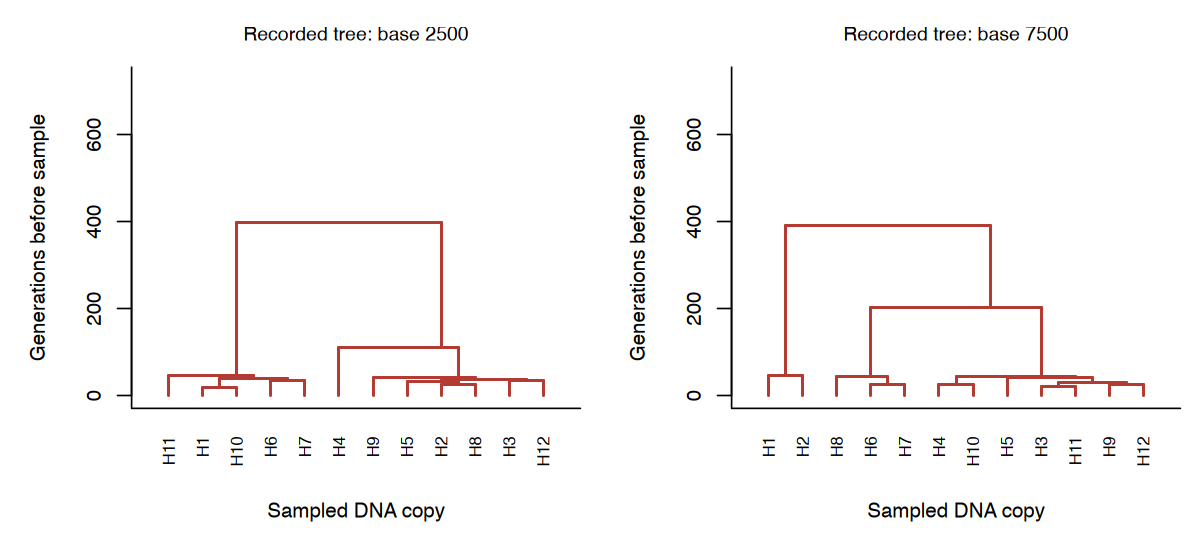

In [4]:
treePositions <- function(nodes) {
    samples <- nodes$node[nodes$is_sample]
    paths <- lapply(samples, function(node) {
        path <- node
        while (nodes$parent[match(node, nodes$node)] >= 0L) {
            node <- nodes$parent[match(node, nodes$node)]
            path <- c(path, node)
        }
        path
    })
    tipOrder <- integer()
    visit <- function(node) {
        if (node %in% samples) tipOrder <<- c(tipOrder, node)
        for (child in nodes$node[nodes$parent == node]) visit(child)
    }
    for (root in nodes$node[nodes$parent == -1L]) visit(root)
    vapply(nodes$node, function(node) {
        children <- tipOrder[vapply(tipOrder, function(sample)
            node %in% paths[[match(sample, samples)]], logical(1))]
        mean(range(match(children, tipOrder)))
    }, numeric(1))
}

drawTree <- function(nodes, title, color, ymax) {
    nodes$x <- treePositions(nodes)
    plot(NA, xlim = c(.4, 12.6), ylim = c(0, ymax), xaxt = "n",
         xlab = "Sampled DNA copy", ylab = "Generations before sample",
         main = title, cex.main = .95, bty = "l")
    for (i in which(nodes$parent >= 0)) {
        parent <- match(nodes$parent[i], nodes$node)
        segments(nodes$x[i], nodes$time[i], nodes$x[i], nodes$time[parent],
                 col = color, lwd = 1.8)
        segments(nodes$x[i], nodes$time[parent], nodes$x[parent],
                 nodes$time[parent], col = color, lwd = 1.8)
    }
    tips <- nodes$is_sample
    axis(1, nodes$x[tips], paste0("H", nodes$node[tips] + 1L),
         tick = FALSE, cex.axis = .8, las = 2, gap.axis = 0)
}
positions <- c(2500L,7500L)
truth_trees <- lapply(ancestry_truth$trees,function(t){
    parent <- setNames(t$edges$parent,t$edges$child)
    ids <- c(t$sample_nodes,setdiff(t$nodes$id,t$sample_nodes))
    p <- unname(parent[as.character(ids)])
    data.frame(node=seq_along(ids)-1L,parent=ifelse(is.na(p),-1L,match(p,ids)-1L),
        time=t$nodes$time[match(ids,t$nodes$id)],is_sample=ids %in% t$sample_nodes)
})
drawFigure("population_arg_trees",function(){
    par(mfrow=c(1,2),mar=c(4.7,4.7,2.4,.7))
    ymax<-max(unlist(lapply(truth_trees,function(t)t$time)))*1.07
    for(pos in positions)drawTree(truth_trees[[as.character(pos)]],
        paste("Recorded tree: base",pos),truth_color,ymax)
})


## Infer the local genealogies

Shared derived variants identify candidate ancestors. The source ancestor
builder groups focal sites by their carrier patterns and derived frequencies,
then extends each ancestor using consensus among those carriers.

Match older ancestors first with the Li–Stephens copying HMM. Then match the
observed copies against the ancestral sequences. The fitted copying paths
give parent–child edges over genomic intervals. Initial node times give an
ordering of ancestors. The matcher probabilities control copying and mismatch.


In [5]:
inferred <- inferAncestry(observed$haplotypes, observed$positions,
    observed$sequenceLength, recombinationProbability = .01,
    mismatchProbability = .001)
reconstructed <- ancestryData(inferred)
stopifnot(identical(reconstructed$observed$haplotypes, observed$haplotypes),
          identical(reconstructed$observed$positions, observed$positions))
print(c(inferred_local_trees = reconstructed$nTrees,
        observed_alleles_reconstructed = length(observed$haplotypes)))


          inferred_local_trees observed_alleles_reconstructed 
                            62                           3312 


## Estimate ages from mutations

For an edge spanning $\ell_e$ bases with child age $t_c$ and parent age $t_p$,

$$M_e\mid\mathcal G,\mu\sim\operatorname{Poisson}\{\mu\ell_e(t_p-t_c)\}.$$

The inside–outside method combines edge likelihoods with conditional
coalescent priors. A rootward pass uses descendant evidence; a leafward pass
uses the rest of the inferred graph. The resulting grid gives each node's
age probabilities. Parent–child constraints give positive branch lengths.

Use the supplied mutation rate and the full panel's diversity-based size
summary, $\widehat N_e=\widehat H/(4\mu)$. Here the full panel supplies the same size summary as the first notebook. Age probabilities
condition on this plug-in value and the inferred topology.

The constant-size prior is a fitted approximation to this changing population.
The main forward model allows recurrent mutations; the copying mismatch
probability is an inference setting, distinct from the biological recombination rate.


In [6]:
mutation_rate <- calibration$mutation_rate
prior_size <- estimateDiversitySize(panel$haplotypes, mutation_rate,
    sequenceLength = panel$sequenceLength)$Ne
dated <- dateAncestry(inferred, mutationRate = mutation_rate,
    populationSize = prior_size, timepoints = 40L)
estimated <- ancestryData(dated)
stopifnot(all(is.finite(dated$nodes$time)),
          all(abs(rowSums(dated$dating$posterior) - 1) < 1e-8),
          identical(estimated$observed$haplotypes, observed$haplotypes))
print(c(prior_Ne_from_observed_diversity = prior_size,
        dated_ancestral_nodes = sum(!dated$nodes$id %in% dated$sampleIds)))


prior_Ne_from_observed_diversity            dated_ancestral_nodes 
                        73.22944                         52.00000 


 position cladePrecision cladeRecall   pairMAE   rootMAE
      125      0.3333333         0.3  62.15125  32.51499
     2500      0.2857143         0.2  89.17248  65.48501
     5000      0.3750000         0.3  41.22187 127.48501
     7500      0.4285714         0.3 108.80156 142.33179
     9875      0.5714286         0.4  57.40081  70.51499


cladePrecision    cladeRecall        pairMAE        rootMAE 
     0.3988095      0.3000000     71.7495935     87.6663576 


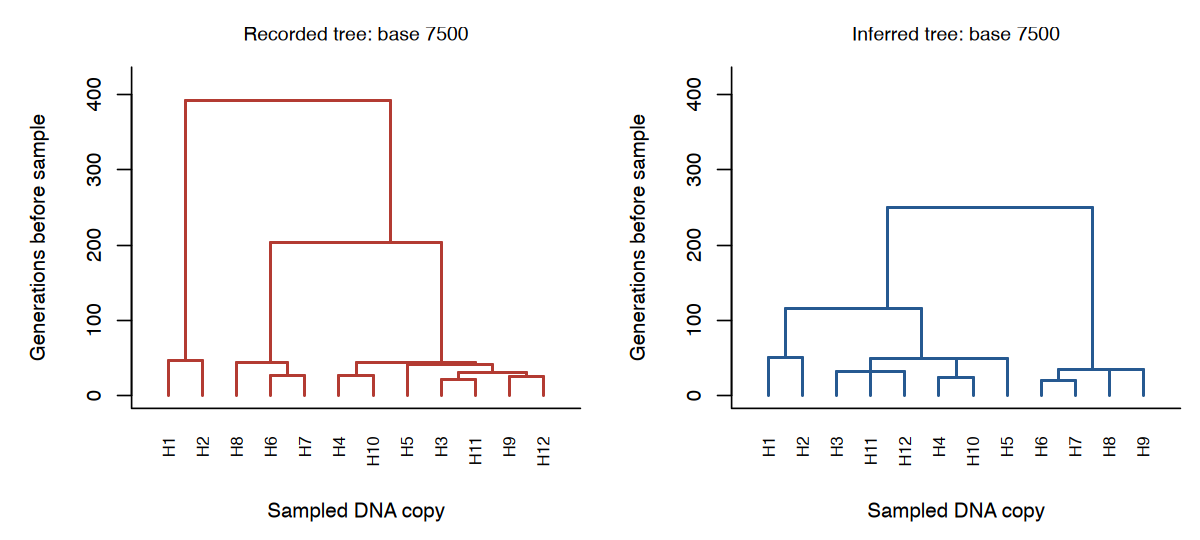

In [7]:
position <- 7500L
drawFigure("population_arg_inference",function(){
    par(mfrow=c(1,2),mar=c(4.7,4.7,2.4,.7))
    ymax<-max(truth_trees[[as.character(position)]]$time,estimated$intervals$tmrca)*1.07
    drawTree(truth_trees[[as.character(position)]],"Recorded tree: base 7500",truth_color,ymax)
    k<-findInterval(position-1,estimated$intervals$left)
    drawTree(estimated$localTrees[[k]],"Inferred tree: base 7500",estimate_color,ymax)
})
# Compare topology and dates at recorded positions, not invented truth intervals.
validation <- do.call(rbind,lapply(c(125L,2500L,5000L,7500L,9875L),function(pos){
    t<-ancestry_truth$trees[[as.character(pos)]]
    truth_at <- structure(list(nodes=data.frame(id=t$nodes$id-1L,time=t$nodes$time,
        flags=as.integer(t$nodes$id %in% t$sample_nodes)),
        edges=data.frame(left=0,right=1,parent=t$edges$parent-1L,child=t$edges$child-1L),
        sampleIds=t$sample_nodes-1L,sequenceLength=1),class=c("hpgR_ancestry","list"))
    est_at<-dated
    take<-est_at$edges$left<=pos-1 & est_at$edges$right>pos-1
    est_at$edges<-est_at$edges[take,];est_at$edges$left<-0;est_at$edges$right<-1
    est_at$sequenceLength<-1
    data.frame(position=pos,t(compareAncestry(est_at,truth_at)$lengthWeighted))
}))
print(validation,row.names=FALSE)
print(colMeans(validation[,-1]))


## SNP discovery in the same chromosome

Use all variants in H1–H12, then keep only variants that differ between H1
and H2. This changes the observed SFS without changing the sampled people
or population. The red prediction uses the generating size schedule;
its infinite-sites expectation approximates the recurrent forward mutation model.


       all_variants discovered_variants 
                276                  75 


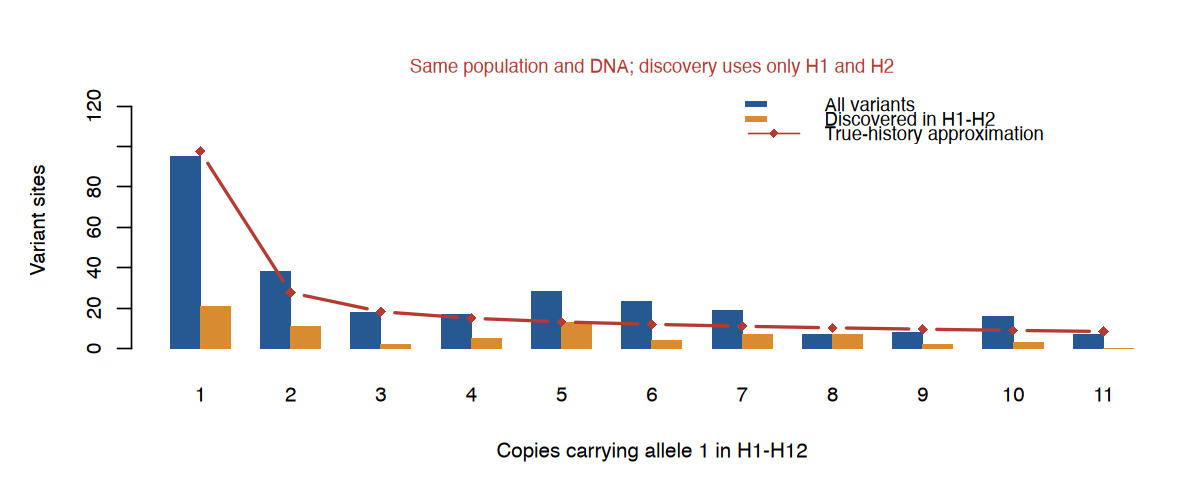

In [8]:
H <- observed$haplotypes
counts <- colSums(H)
all_sfs <- tabulate(counts, nrow(H) - 1L)
discovered <- H[1, ] != H[2, ]
discovered_sfs <- tabulate(counts[discovered], nrow(H) - 1L)
schedule <- populationSizeSchedule(populationHistoryDesign()$candidates$recent_founding,calibration)
recent_sizes <- head(c(20L,schedule[-1L]),-1L)
expectation <- expectedHistorySFS(12,c(100,recent_sizes),calibration$mutation_rate,10000)
drawFigure("population_arg_spectrum", function() {
    par(mar = c(4.7, 4.7, 3.3, 1), bg = "white")
    x <- barplot(rbind(all_sfs, discovered_sfs), beside = TRUE,
        col = c(estimate_color, "#D88B31"), border = NA,
        names.arg = seq_len(nrow(H) - 1L), xlab = "Copies carrying allele 1 in H1-H12",
        ylab = "Variant sites", ylim = c(0, max(all_sfs, expectation) * 1.3))
    lines(colMeans(x), expectation, col = truth_color, type = "b", pch = 18, lwd = 2)
    legend("topright", c("All variants", "Discovered in H1-H2", "True-history approximation"),
        fill = c(estimate_color, "#D88B31", NA), border = NA,
        col = c(NA, NA, truth_color), lty = c(NA, NA, 1),
        pch = c(NA, NA, 18), bty = "n", cex = .9, y.intersp = 1.6)
    mtext("Same population and DNA; discovery uses only H1 and H2",
          side = 3, line = .6, col = truth_color, cex = .9)
}, height = 4)
print(c(all_variants = sum(all_sfs), discovered_variants = sum(discovered_sfs)))


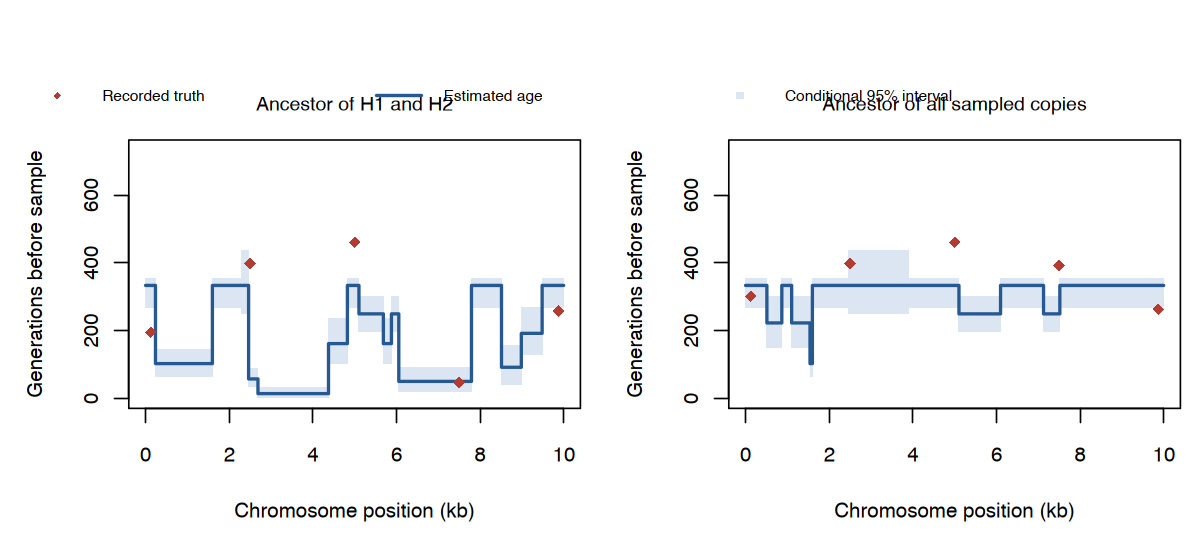

In [9]:
drawFigure("population_arg_ages", function() {
    par(mfrow = c(1, 2), mar = c(4.7, 4.6, 2.6, .7), oma = c(0, 0, 2.4, 0))
    for (field in c("pair_time", "tmrca")) {
        node_field <- if (field == "pair_time") "pair_node" else "root_node"
        interval <- estimated$intervals
        nodes <- interval[[node_field]]
        bounds <- t(vapply(nodes, function(node) {
            p <- dated$dating$posterior[node + 1L, ]
            vapply(c(.025, .975), function(q)
                dated$dating$timepoints[which(cumsum(p) >= q)[1L]], 0)
        }, c(0, 0)))
        x <- c(interval$left, tail(interval$right, 1L))/1000
        y <- c(interval[[field]], tail(interval[[field]], 1L))
        plot(NA, xlim = c(0, observed$sequenceLength/1000),
            ylim = c(0, max(unlist(lapply(truth_trees,function(t)t$time)), bounds) * 1.08),
            xlab = "Chromosome position (kb)", ylab = "Generations before sample",
            main = if (field == "pair_time") "Ancestor of H1 and H2" else
                "Ancestor of all sampled copies", cex.main = .95)
        for (j in seq_len(nrow(interval))) rect(interval$left[j]/1000, bounds[j,1],
            interval$right[j]/1000, bounds[j,2], col = "#DCE6F2", border = NA)
        lines(x, y, type = "s", col = estimate_color, lwd = 2)
        true_positions <- c(125L,2500L,5000L,7500L,9875L)
        true_ages <- vapply(ancestry_truth$trees[as.character(true_positions)],function(t){
            q<-pgTreeSummaries(t)
            if(field=="pair_time")q$pair_time else q$TMRCA
        },0)
        points((true_positions-1)/1000,true_ages,pch=18,col=truth_color,cex=1.1)
    }
    par(xpd = NA)
    legend(grconvertX(.5, "ndc", "user"), grconvertY(.99, "ndc", "user"),
        c("Recorded truth", "Estimated age", "Conditional 95% interval"),
        col = c(truth_color, estimate_color, "#DCE6F2"),
        lty = c(NA,1,NA), lwd = c(2,2,NA), pch = c(18,NA,15),
        xjust = .5, yjust = 1, horiz = TRUE, bty = "n", cex = .75)
})


In [10]:
# Refining the time grid checks numerical resolution.
finer <- dateAncestry(inferred, mutation_rate, prior_size, timepoints = 80L)
grid_change <- mean(abs(dated$dating$mean - finer$dating$mean)[
    !dated$nodes$id %in% dated$sampleIds])
print(c(mean_age_change_with_finer_grid = grid_change))


mean_age_change_with_finer_grid 
                      0.5939651 


The inferred tables reconstruct the observed alleles. Recorded point trees
supply independent checks of topology and age. The age intervals condition
on the inferred topology, mutation rate and fitted constant-size prior;
they do not include uncertainty about the whole demographic history.

Sources: Pritchard, Sections 2.2, 2.3 and 3.3; Kelleher et al. (2019);
Wohns et al. (2022); source-derived functions from Daniel Nachun's tskitR.


## Simulate linked ancestry under the same demographic model

Use the same twelve haplotypes, 10,000-base chromosome, 0.2-Morgan map and
symmetric binary mutation rate. The source-derived Hudson simulator follows
sample ancestors with piecewise-constant sizes for the same 60 generations,
then ancestral size 100. This is a new coalescent realization, not the recorded
forward tree. The continuous clock and ancestral-equilibrium tail are approximations.


In [11]:
coalescent <- simulateAncestry(samples=6L,populationSize=100,
    sequenceLength=10000,recombinationRate=.2/9999,
    populationSizes=rev(recent_sizes),seed=20261104L,recordFullArg=TRUE)
coalescent_dna <- mutateAncestry(coalescent,calibration$mutation_rate,
    seed=20261105L,model="binary")
coalescent_data <- ancestryData(coalescent_dna)
print(c(sampled_copies=coalescent_data$nHaplotypes,
    mutation_sites=coalescent_data$nSites,local_trees=coalescent_data$nTrees,
    recorded_intervals=coalescent_data$nRecordedTrees))
stopifnot(coalescent_data$nHaplotypes==12L,coalescent_data$nTrees>1L)


    sampled_copies     mutation_sites        local_trees recorded_intervals 
                12                252                149                193 
